# 1. Pre-processing: from satellite products to downscaling inputs

**Daily 30 m snow cover for Reynolds Creek and Dry Creek, Idaho.** This notebook is the first of three that walk through the workflow on one example day at Reynolds Creek:

1. **Pre-processing** (this notebook): the 30 m grid, the daily MODIS snow fraction, a Landsat snow map, and the snow-persistence ranking.
2. **Downscaling**: placing the MODIS snow fraction on the 30 m grid.
3. **Verification**: comparing the product with ground snow depth and with held-out Landsat maps.

The notebooks run from the `notebooks/` folder of the data release and read the released files next to it. The production scripts are in `../code/`; the notebooks call the same functions where they can and repeat short pieces of logic inline where that is clearer.

*Disclosure: the processing code and these notebooks were written with the assistance of Claude (Anthropic), working under the direction of the authors.*

In [1]:
import os, sys, io, tarfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4

ROOT = Path("..")                      # essd_draft/
CODE = ROOT / "code"
DATA = Path("data"); DATA.mkdir(exist_ok=True)
os.environ["SNOW_DOMAIN"] = "rcew"     # the pipeline code reads the domain from this variable
sys.path.insert(0, str(CODE))

SEASONS_NC = ROOT / "rcew_snow_seasons_30m_v1.nc"
DAILY_STEM = "rcew_snowcover_daily_30m_v1"   # one file, or parts along time (see daily_io.py)
MODIS_TAR = ROOT / "inputs" / "rcew_mod10a1f_window_2000_2026.tar"
EXAMPLE_DATE = pd.Timestamp("2019-03-18")   # clear Landsat 8 overpass with a partly snow-covered watershed

plt.rcParams.update({"font.size": 9, "figure.dpi": 110, "axes.facecolor": "#d4d4d4"})   # grey = outside or no data
from matplotlib.colors import LinearSegmentedColormap
SNOW = LinearSegmentedColormap.from_list("snow", ["#5c4326", "#9c7a4e", "#cdbb98", "#e6e9ea", "#ffffff"])   # bare ground to snow

## 1.1 The 30 m grid and its static layers

Everything is computed on a 30 m UTM 11N grid (EPSG:32611). Elevation, slope and aspect come from a 10 m DEM averaged to 30 m. The forest flag marks cells whose median summer NDVI (Landsat, July-August) is at least 0.45. Production script: `build_grid.py`.

In [2]:
S = netCDF4.Dataset(SEASONS_NC)
grab = lambda k: np.ma.filled(S[k][:].astype(float), np.nan)
x, y = S["x"][:], S["y"][:]
region = np.ma.filled(S["region"][:], 0).astype(int)
inside = region > 0
elev, slope, aspect = grab("elevation"), grab("slope"), grab("aspect")
forest = np.ma.filled(S["forest"][:], 0).astype(bool)
persistence = grab("snow_persistence")
extent = [x.min() - 15, x.max() + 15, y.min() - 15, y.max() + 15]
NY, NX = region.shape
print(f"grid {NY} x {NX} cells at 30 m, {inside.sum() * 900 / 1e6:.0f} km2 inside the watershed, "
      f"{np.nanmin(elev):.0f}-{np.nanmax(elev):.0f} m, forest share {forest[inside].mean():.0%}")

grid 1030 x 560 cells at 30 m, 240 km2 inside the watershed, 1104-2241 m, forest share 15%


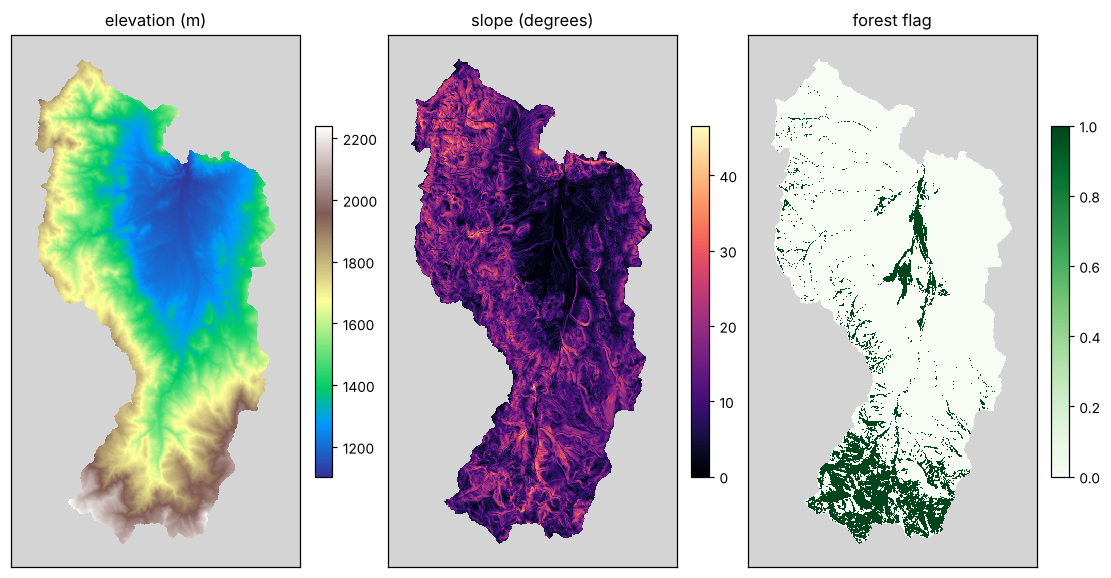

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(10, 5.5), constrained_layout=True)
for ax, fld, cmap, lab in [(axs[0], elev, "terrain", "elevation (m)"), (axs[1], slope, "magma", "slope (degrees)"),
                           (axs[2], np.where(inside, forest, np.nan), "Greens", "forest flag")]:
    im = ax.imshow(fld, extent=extent, cmap=cmap, interpolation="nearest")
    ax.set_title(lab); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.6)
plt.show()

## 1.2 Daily MODIS snow fraction

The daily input is **MOD10A1F v61**, the cloud-gap-filled MODIS/Terra NDSI snow cover at 463 m (tile h09v04). `fetch_tiles.py` downloads each daily tile from NSIDC with an Earthdata token, cuts the window that covers the watershed and discards the tile:

```
SNOW_DOMAIN=rcew TILE_WINDOW=1591,1680,1075,1254 python3 ../code/fetch_tiles.py MOD10A1F 61 2000-02-24 2026-09-30 mod/
```

The release includes those windows (`inputs/rcew_mod10a1f_window_2000_2026.tar`, 9,716 days), so the download is not repeated here.

NDSI (0-100) is converted to fractional snow-covered area with the relation of Salomonson & Appel (2004): `fSCA = clip(-0.01 + 1.45 * NDSI / 100, 0, 1)`. Values above 100 are fill codes. `Cloud_Persistence` counts the days since the pixel was last seen clear; pixels older than 10 days are treated as missing.

In [4]:
def modis_day(date):
    """One day's MOD10A1F window (89 x 179 pixels at 463 m) from the archive of pre-cut windows."""
    name = f"mod/A{date.year}{date.dayofyear:03d}.npz"
    with tarfile.open(MODIS_TAR) as t:
        return dict(np.load(io.BytesIO(t.extractfile(name).read())))

2019-03-18: window (89, 179), 94% of pixels seen clear today, mean fSCA 0.18


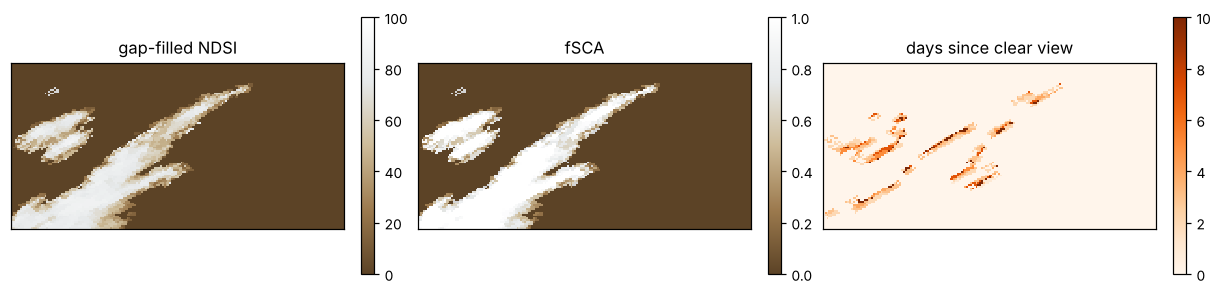

In [5]:
from downscale import ndsi_to_fsca

m = modis_day(EXAMPLE_DATE)
ndsi = m["CGF_NDSI_Snow_Cover"].astype(float)
cloud_age = m["Cloud_Persistence"].astype(float)
fsca_modis = np.where((ndsi <= 100) & (cloud_age <= 10), ndsi_to_fsca(ndsi), np.nan)
seen_today = m["MOD10A1_NDSI_Snow_Cover"] <= 100
print(f"{EXAMPLE_DATE.date()}: window {ndsi.shape}, {seen_today.mean():.0%} of pixels seen clear today, "
      f"mean fSCA {np.nanmean(fsca_modis):.2f}")

fig, axs = plt.subplots(1, 3, figsize=(11, 3), constrained_layout=True)
for ax, fld, cmap, lab, vmax in [(axs[0], np.where(ndsi <= 100, ndsi, np.nan), SNOW, "gap-filled NDSI", 100),
                                 (axs[1], fsca_modis, SNOW, "fSCA", 1), (axs[2], cloud_age, "Oranges", "days since clear view", 10)]:
    im = ax.imshow(fld, cmap=cmap, vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_title(lab); ax.set_xticks([]); ax.set_yticks([]); fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

## 1.3 A 30 m snow map from Landsat

Landsat and Sentinel-2 give the fine-scale snow pattern on the days they see the ground. The production run read every Landsat 4-9 Collection 2 Level-2 scene (Tier 1) and every Sentinel-2 L2A scene over the watershed (3,696 usable scenes at Reynolds Creek; `fetch_landsat_c2.py`, `fetch_s2.py`).

Here we read one Landsat 8 scene from Microsoft Planetary Computer, the same source, and apply the snow test of `process_hires.py`. The scene is cached in `data/` after the first run, so the notebook also runs offline.

In [6]:
import json, urllib.request
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.windows import from_bounds

SCENE = "LC08_L2SP_042030_20190318_02_T1"
cache = DATA / f"{SCENE}.npz"
X0, Y1 = extent[0], extent[3]; X1, Y0 = extent[1], extent[2]
DST = rasterio.transform.from_origin(X0, Y1, 30, 30)


def warp(href, token, resampling, dtype, nodata):
    with rasterio.open(f"/vsicurl/{href}?{token}") as r:
        w = from_bounds(X0 - 200, Y0 - 200, X1 + 200, Y1 + 200, r.transform).round_offsets().round_lengths()
        a = r.read(1, window=w, boundless=True, fill_value=nodata)
        o = np.full((NY, NX), nodata, dtype)
        reproject(a, o, src_transform=r.window_transform(w), src_crs=r.crs, dst_transform=DST, dst_crs="EPSG:32611",
                  resampling=resampling, src_nodata=nodata, dst_nodata=nodata)
    return o


if not cache.exists():
    api = "https://planetarycomputer.microsoft.com/api"
    item = json.load(urllib.request.urlopen(f"{api}/stac/v1/collections/landsat-c2-l2/items/{SCENE}", timeout=60))
    token = json.load(urllib.request.urlopen(f"{api}/sas/v1/token/landsat-c2-l2", timeout=60))["token"]
    bands = {}
    for name, asset in [("green", "green"), ("red", "red"), ("nir", "nir08"), ("swir1", "swir16")]:
        dn = warp(item["assets"][asset]["href"], token, Resampling.average, np.float32, 0)
        bands[name] = np.where(dn > 0, dn * 0.0000275 - 0.2, np.nan).astype(np.float32)   # C2 L2 scale and offset
    bands["qa_pixel"] = warp(item["assets"]["qa_pixel"]["href"], token, Resampling.nearest, np.uint16, 1)
    np.savez_compressed(cache, **bands)
L = dict(np.load(cache))
print({k: v.shape for k, v in L.items()})

{'green': (1030, 560), 'red': (1030, 560), 'nir': (1030, 560), 'swir1': (1030, 560), 'qa_pixel': (1030, 560)}


**Snow test** (per clear cell), with `NDSI = (green - swir1) / (green + swir1)`:

- open cells: NDSI >= 0.40, NIR >= 0.11 and green >= 0.10 (the SNOMAP test);
- forest cells: NDSI >= 0.20, NIR >= 0.11 and green >= 0.08, because canopy lowers the NDSI of a snow-covered stand.

**Clear** means not fill, and not flagged cloud, cloud shadow or cirrus in `QA_PIXEL`. Cloud masks often call bright snow cloud, so a cell flagged cloud with NDSI >= 0.6 and SWIR < 0.15 is kept and counted as snow (real cloud is bright in the SWIR).

clear 86% of the watershed, snow on 36% of clear cells


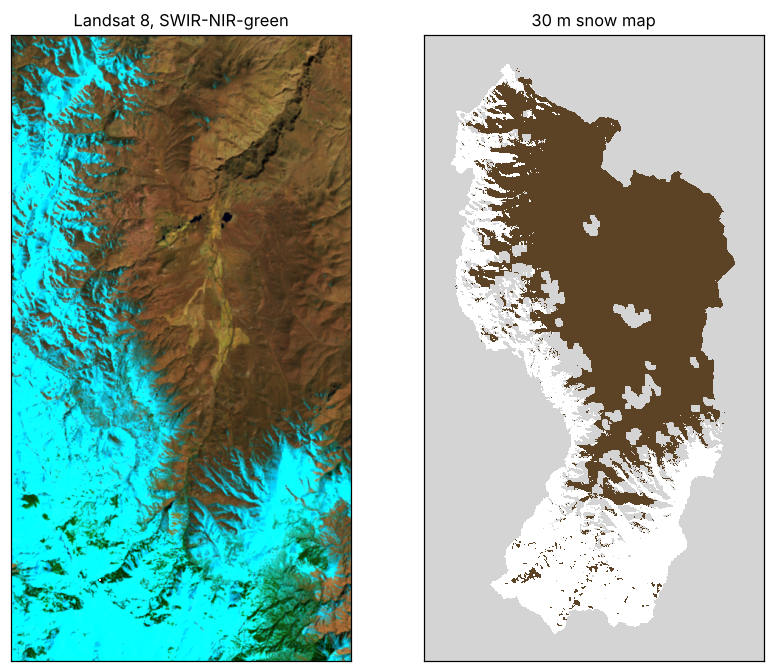

In [7]:
bits = lambda a, start, n=1: (a.astype(np.int32) >> start) & ((1 << n) - 1)

q = L["qa_pixel"]
cloud = (bits(q, 3) == 1) | (bits(q, 4) == 1) | (bits(q, 8, 2) == 3) | (bits(q, 14, 2) == 3)
fill = (bits(q, 0) == 1) | ~np.isfinite(L["green"])
ndsi30 = (L["green"] - L["swir1"]) / (L["green"] + L["swir1"])
nir_ok = L["nir"] >= 0.11
snow = np.where(forest, (ndsi30 >= 0.20) & nir_ok & (L["green"] >= 0.08),
                (ndsi30 >= 0.40) & nir_ok & (L["green"] >= 0.10))
rescue = cloud & (ndsi30 >= 0.6) & (L["swir1"] < 0.15) & nir_ok
clear = (~cloud | rescue) & ~fill & np.isfinite(ndsi30)
landsat_snow = np.full((NY, NX), 255, np.uint8)          # 0 no snow, 1 snow, 255 not clear
landsat_snow[clear] = snow[clear]
print(f"clear {clear[inside].mean():.0%} of the watershed, snow on {snow[inside & clear].mean():.0%} of clear cells")

rgb = np.clip(np.dstack([L["swir1"], L["nir"], L["green"]]) / 0.6, 0, 1)    # snow shows cyan
show = np.where(inside & clear, snow.astype(float), np.nan)
fig, axs = plt.subplots(1, 2, figsize=(7.5, 6), constrained_layout=True)
axs[0].imshow(rgb, extent=extent); axs[0].set_title("Landsat 8, SWIR-NIR-green")
axs[1].imshow(show, extent=extent, cmap=SNOW, vmin=0, vmax=1, interpolation="nearest"); axs[1].set_title("30 m snow map")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()
np.savez_compressed(DATA / "example_landsat_snow_20190318.npz", snow=landsat_snow)

## 1.4 Snow persistence: the ranking used for downscaling

Stacking all such maps gives, for every 30 m cell, the **share of clear February-June views in which the cell is snow covered** (`build_persistence.py`). Cells with high persistence hold snow longest, so this is the order in which the watershed fills with snow and empties again.

Under forest, optical sensors miss snow beneath the canopy and the observed persistence is biased low. There the value is replaced by a prediction from elevation and spring insolation, fitted on the open cells (the "terrain model"; r = 0.92-0.93 on open cells at Reynolds Creek). The released `snow_persistence` layer already includes that replacement, and the `forest` flag marks where it applies.

This builds on Walters et al. (2014, *Remote Sensing of Environment* 152:413), who ranked cells by a terrain score of insolation and relative elevation. Notebook 2 compares the two rankings.

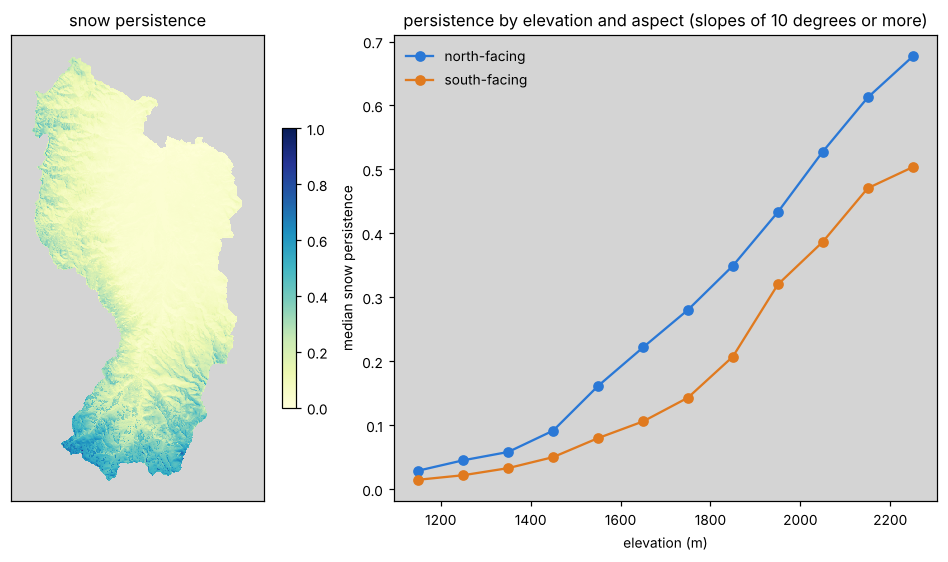

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 5), constrained_layout=True, gridspec_kw=dict(width_ratios=[1, 1.5]))
im = axs[0].imshow(persistence, extent=extent, cmap="YlGnBu", vmin=0, vmax=1, interpolation="nearest")
axs[0].set_title("snow persistence"); axs[0].set_xticks([]); axs[0].set_yticks([]); fig.colorbar(im, ax=axs[0], shrink=0.6)
north = (aspect >= 315) | (aspect < 45); south = (aspect >= 135) & (aspect < 225)
steep = inside & (slope >= 10)
for sel, col, lab in [(steep & north, "#2a78d6", "north-facing"), (steep & south, "#e07a1f", "south-facing")]:
    band = np.floor(elev[sel] / 100) * 100
    med = pd.Series(persistence[sel]).groupby(band).median()
    axs[1].plot(med.index + 50, med.values, "o-", color=col, label=lab)
axs[1].set_xlabel("elevation (m)"); axs[1].set_ylabel("median snow persistence"); axs[1].legend(frameon=False)
axs[1].set_title("persistence by elevation and aspect (slopes of 10 degrees or more)")
plt.show()

**Outputs of this step:** the daily MODIS fSCA windows, the static grid layers and the snow-persistence ranking. Notebook 2 combines them.